# ¿Coincide lo que escriben los clientes con sus 4,5 estrellas?

**Cliente:** WeLoveReviews · **Negocio analizado:** Harbor House Café · **Dataset:** 500 reseñas escritas

Notebook de comunicación: recorre objetivos → EDA → limpieza → plan y modelo → resultados → conclusiones.

## 1. Objetivos

La account manager necesita responder, en términos simples, antes de presentar el reporte al cliente:

1. **¿Cuántas de las 500 reseñas se leen como positivas, neutrales o negativas?**
2. **¿Esa distribución coincide con el promedio de 4,5 / 5 estrellas del negocio?**
3. **Si hay diferencia, ¿de dónde viene?** ¿El texto es más negativo que la nota, o el modelo se equivoca?

**Cómo lo respondemos:** integramos un modelo preentrenado de Hugging Face (sin entrenar nada),
clasificamos cada reseña y comparamos el resultado con la puntuación real que dejó cada cliente,
que usamos como "verdad de referencia".

## 2. Configuración

Rutas del proyecto y modelo **fijado por commit**: si el autor publica otra versión en `main`,
este análisis seguirá usando exactamente la misma.

In [1]:
import os
import time
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display

os.environ.setdefault("HF_HUB_DISABLE_PROGRESS_BARS", "1")
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")

pd.set_option("display.max_colwidth", 200)
pd.set_option("display.width", 200)

# El notebook puede ejecutarse desde src/ (VS Code, nbconvert) o desde la raíz del repo.
PROJECT_ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
RAW_PATH = PROJECT_ROOT / "data" / "raw" / "reviews.csv"

MODEL_NAME = "nlptown/bert-base-multilingual-uncased-sentiment"
MODEL_REVISION = "8f6f4e3a8f70be4b65d3a4a8762b6d781cda240d"  # commit fijado

BAND_ORDER = ["Positivo", "Neutral", "Negativo"]


def stars_to_band(stars: int) -> str:
    """1-2 estrellas = Negativo, 3 = Neutral, 4-5 = Positivo."""
    if stars <= 2:
        return "Negativo"
    if stars == 3:
        return "Neutral"
    return "Positivo"


def band_pct(series: pd.Series) -> pd.Series:
    """Porcentaje por banda, siempre en el mismo orden."""
    return (series.value_counts(normalize=True).reindex(BAND_ORDER, fill_value=0) * 100).round(1)


print("Raíz del proyecto:", PROJECT_ROOT)

Raíz del proyecto: /workspaces/aie-pte3-machine-learning-python-template-Nestornegrin


## 3. Exploración de datos (EDA)

### 3.1 Estructura y calidad básica

In [2]:
df_raw = pd.read_csv(RAW_PATH)
print("Filas x columnas:", df_raw.shape)
print("\nTipos:")
print(df_raw.dtypes)
print("\nNulos por columna:")
print(df_raw.isna().sum())
print("\nreview_id único:", df_raw["review_id"].is_unique)
print("Ratings fuera de 1-5:", (~df_raw["rating"].between(1, 5)).sum())
print("Textos con espacios sobrantes:", (df_raw["review_text"] != df_raw["review_text"].str.strip()).sum())
df_raw.head()

Filas x columnas: (500, 3)

Tipos:
review_id       int64
rating          int64
review_text    object
dtype: object

Nulos por columna:
review_id      0
rating         0
review_text    0
dtype: int64

review_id único: True
Ratings fuera de 1-5: 0
Textos con espacios sobrantes: 0


,review_id,rating,review_text
0,1,5,Visited Harbor House Café last weekend. Great spot to work or catch up with friends. Every dish was bursting with flavor. Worth every penny. Already planning my next visit.
1,2,5,Tried Harbor House Café after seeing it recommended online. The coffee was rich and perfectly brewed. Great spot to work or catch up with friends. Great value for what you get. Five stars without ...
2,3,5,Tried Harbor House Café after seeing it recommended online. Great spot to work or catch up with friends. The seasonal menu never disappoints. Great value for what you get. Already planning my next...
3,4,5,Visited Harbor House Café last weekend. The staff were warm and attentive. The music and decor set the perfect mood. Worth every penny. Five stars without hesitation.
4,5,5,Grabbed a quick coffee at Harbor House Café this morning. They went out of their way to accommodate my allergy. The food was absolutely delicious. Five stars without hesitation.


Dataset limpio de partida: **500 reseñas, 3 columnas, sin nulos, IDs únicos y ratings válidos**.

### 3.2 Distribución de la puntuación humana

Comprobamos que el promedio realmente es 4,5 y cómo se reparte.

Promedio de estrellas: 4.50


,reseñas,%
rating,,
1,12,2.4
2,18,3.6
3,38,7.6
4,72,14.4
5,360,72.0


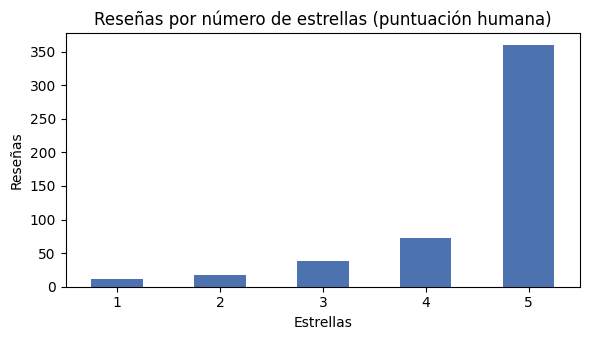

In [3]:
rating_counts = df_raw["rating"].value_counts().sort_index()
rating_table = pd.DataFrame({
    "reseñas": rating_counts,
    "%": (rating_counts / len(df_raw) * 100).round(1),
})
print(f"Promedio de estrellas: {df_raw['rating'].mean():.2f}")
display(rating_table)

ax = rating_counts.plot(kind="bar", color="#4C72B0", figsize=(6, 3.5))
ax.set_title("Reseñas por número de estrellas (puntuación humana)")
ax.set_xlabel("Estrellas")
ax.set_ylabel("Reseñas")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

El promedio es **exactamente 4,50**. La distribución está muy sesgada hacia arriba:
**72 % de las reseñas son de 5 estrellas** y solo un 6 % son de 1–2.

### 3.3 Longitud y forma del texto

In [4]:
lengths = pd.DataFrame({
    "caracteres": df_raw["review_text"].str.len(),
    "palabras": df_raw["review_text"].str.split().str.len(),
})
display(lengths.describe().round(1))

df_tmp = df_raw.assign(palabras=lengths["palabras"])
display(df_tmp.groupby("rating")["palabras"].mean().round(1).to_frame("palabras medias"))

,caracteres,palabras
count,500.0,500.0
mean,170.2,29.1
std,27.1,4.8
min,86.0,14.0
25%,155.0,26.0
50%,173.0,29.0
75%,189.0,32.0
max,230.0,42.0


,palabras medias
rating,
1,30.2
2,26.4
3,26.8
4,30.5
5,29.2


Reseñas **cortas (14–42 palabras)**: muy por debajo del límite de 512 tokens de BERT, así que no
perderemos texto por truncado. La longitud no cambia de forma relevante según la nota.

### 3.4 Duplicados, idioma y estilo

In [5]:
dup_mask = df_raw["review_text"].duplicated(keep=False)
print("Textos duplicados (pares):", df_raw["review_text"].duplicated().sum())
print("¿Los duplicados tienen la misma nota?:",
      df_raw[dup_mask].groupby("review_text")["rating"].nunique().eq(1).all())

print("\nNegocios mencionados:", df_raw["review_text"].str.extract(r"(Harbor House Café)")[0].dropna().unique())
print("Reseñas en las que se nombra el local:", df_raw["review_text"].str.contains("Harbor House Café").sum())
print("Reseñas con 'i' en minúscula como pronombre:", df_raw["review_text"].str.contains(r"\bi\b").sum())

Textos duplicados (pares): 7
¿Los duplicados tienen la misma nota?: True

Negocios mencionados: ['Harbor House Café']
Reseñas en las que se nombra el local: 433
Reseñas con 'i' en minúscula como pronombre: 43


- Hay **7 textos duplicados**, cada uno con su propio `review_id` y la misma nota.
- Todas las reseñas están **en inglés** y hablan del mismo local: **Harbor House Café**.
- Aparece "i" en minúscula como pronombre; no afecta porque el modelo es *uncased* (pasa todo a minúsculas).

### 3.5 Estructura de las reseñas: frases que se repiten

Las reseñas se construyen combinando frases. Ver qué frases aparecen y con qué notas explica mucho.

In [6]:
sentences = (
    df_raw.assign(sentence=df_raw["review_text"].str.split(r"(?<=[.!?])\s+"))
    .explode("sentence")
)
print("Frases distintas en todo el dataset:", sentences["sentence"].nunique())

sentence_by_rating = pd.crosstab(sentences["sentence"], sentences["rating"])
sentence_by_rating["total"] = sentence_by_rating.sum(axis=1)
sentence_by_rating.sort_values("total", ascending=False).head(15)

Frases distintas en todo el dataset: 69


rating,1,2,3,4,5,total
sentence,,,,,,
This is now my go-to spot.,0,0,0,8,84,92
Will definitely be back!,0,0,0,11,74,85
Five stars without hesitation.,0,0,0,14,70,84
Came to Harbor House Café for a birthday brunch.,2,2,5,12,58,79
Tried Harbor House Café after seeing it recommended online.,1,2,5,13,55,76
Already planning my next visit.,0,0,0,6,69,75
Regular customer at Harbor House Café here.,5,3,7,12,47,74
Grabbed a quick coffee at Harbor House Café this morning.,1,5,4,14,49,73
Stopped by Harbor House Café for the first time.,1,3,5,8,53,70


Solo hay **69 frases distintas**. Muchas son claramente positivas y otras claramente negativas,
pero hay un grupo que mezcla las dos cosas en la misma frase. Lo miramos a continuación.

### 3.6 Reseñas mixtas: queja + "pero…"

In [7]:
CONTRAST_PATTERN = r", but (?:honestly the food made up for it|overall a solid experience)"
df_raw["is_mixed"] = df_raw["review_text"].str.contains(CONTRAST_PATTERN)

print("Reseñas con queja + giro positivo:", int(df_raw["is_mixed"].sum()))
display(pd.crosstab(df_raw["is_mixed"], df_raw["rating"], margins=True, margins_name="total"))

print("Ejemplos:")
for text in df_raw.loc[df_raw["is_mixed"], "review_text"].head(4):
    print("-", text)

Reseñas con queja + giro positivo: 90


rating,1,2,3,4,5,total
is_mixed,,,,,,
False,12,18,38,3,339,410
True,0,0,0,69,21,90
total,12,18,38,72,360,500


Ejemplos:
- The pastries were incredible. The staff seemed annoyed to be there, but honestly the food made up for it. This is now my go-to spot.
- Tried Harbor House Café after seeing it recommended online. The sourdough bread alone is worth the visit. The staff were polite but a bit slow, but overall a solid experience. Five stars without hesitation.
- Regular customer at Harbor House Café here. The pastries were incredible. The staff were polite but a bit slow, but overall a solid experience. Might give it another shot.
- The coffee was rich and perfectly brewed. The staff were polite but a bit slow, but overall a solid experience. This is now my go-to spot.


**90 reseñas (18 %)** contienen una **queja de servicio** (esperas, camarero que se equivoca,
personal antipático) seguida de *"but honestly the food made up for it"* o *"but overall a solid experience"*.
**Todas tienen 4 o 5 estrellas**: el cliente se queja del servicio pero valora bien el conjunto.
Dato clave: **69 de las 72 reseñas de 4 ★ son mixtas**. En este negocio, un 4 suele significar
"me gustó, pero el servicio falló".

### 3.7 Insights de la EDA

1. **Datos limpios**: sin nulos, IDs únicos, ratings válidos. El promedio de 4,50 es correcto.
2. **La "verdad" humana es muy positiva**: 86,4 % positivas (4–5 ★), 7,6 % neutrales (3 ★) y 6,0 % negativas (1–2 ★).
3. **Reseñas cortas**: no hay riesgo de truncado.
4. **Riesgo principal para el modelo**: el 18 % de las reseñas son mixtas, con quejas de **servicio**
   y nota alta (casi todos los 4 ★ y 21 reseñas de 5 ★). Un modelo entrenado con reseñas de **productos** puede quedarse con la queja e ignorar el "pero".
5. **Ruido en la nota humana**: algunas reseñas de 4 ★ terminan en tono tibio (*"Might give it another shot"*),
   así que la nota no siempre es una etiqueta perfecta del texto.

## 4. Limpieza

Propuesta a partir de la EDA, deliberadamente mínima para no alterar lo que dijo el cliente:

| Decisión | Motivo |
|---|---|
| Recortar espacios del texto | Higiene; hoy no cambia nada |
| Descartar textos vacíos o ratings fuera de 1–5 | Validación defensiva; hoy no elimina nada |
| **Mantener los 7 duplicados** | Tienen `review_id` distinto y forman parte de las 500 que se entregan |
| No pasar a minúsculas ni quitar tildes | El tokenizador del modelo ya lo hace |
| Crear `human_band` a partir de `rating` | Para comparar con el modelo en las mismas bandas |

In [8]:
df = df_raw.copy()
df["review_text"] = df["review_text"].astype(str).str.strip()
df = df[df["review_text"].ne("") & df["rating"].between(1, 5)].reset_index(drop=True)
df["human_band"] = df["rating"].map(stars_to_band)

print("Reseñas tras la limpieza:", len(df))
band_pct(df["human_band"]).to_frame("% según puntuación humana")

Reseñas tras la limpieza: 500


,% según puntuación humana
human_band,
Positivo,86.4
Neutral,7.6
Negativo,6.0


## 5. Plan de acción y justificación del modelo

**Modelo:** `nlptown/bert-base-multilingual-uncased-sentiment`, fijado en el commit `8f6f4e3`.

- Predice **de 1 a 5 estrellas**, la misma escala que usa el negocio, lo que permite comparar directamente
  con el 4,5 y no solo con "positivo/negativo".
- Es multilingüe y *uncased*, adecuado para reseñas cortas en inglés.
- **Riesgo conocido**: se entrenó con reseñas de **productos**. Nuestro dataset es de **servicios** y la EDA
  ya detectó un 18 % de reseñas mixtas con quejas de servicio. **Hipótesis inicial:** los falsos negativos
  se concentrarán en esas reseñas mixtas. La comprobaremos con los resultados.

**Plan:**

1. Cargar el modelo **una sola vez** con `pipeline()` y procesar las 500 reseñas **por lotes**.
2. Mapear estrellas a bandas: 1–2 = Negativo, 3 = Neutral, 4–5 = Positivo.
3. Comparar la distribución del modelo con la humana y con el promedio de 4,5.
4. Buscar falsos negativos (nota 4–5, modelo 1–2) y analizar sus patrones.
5. Revisar a mano una muestra de 19 reseñas.
6. Traducir los resultados a conclusiones para la account manager.

## 6. Inferencia sobre las 500 reseñas

El modelo se carga **fuera de cualquier bucle**. Los pesos se descargan a la caché local de
Hugging Face (`~/.cache/huggingface`), **no al repositorio**.

In [9]:
from transformers import pipeline
from transformers.utils import logging as hf_logging

hf_logging.set_verbosity_error()

start = time.perf_counter()
classifier = pipeline(
    "text-classification",
    model=MODEL_NAME,
    revision=MODEL_REVISION,
    device=-1,  # CPU
)
print(f"Modelo cargado una vez en {time.perf_counter() - start:.1f} s")
print("Etiquetas del modelo:", list(classifier.model.config.id2label.values()))

Modelo cargado una vez en 0.9 s
Etiquetas del modelo: ['1 star', '2 stars', '3 stars', '4 stars', '5 stars']


In [10]:
start = time.perf_counter()
outputs = classifier(df["review_text"].tolist(), batch_size=32, truncation=True)  # mismo clasificador para todas
print(f"500 reseñas clasificadas en {time.perf_counter() - start:.1f} s")

preds = pd.DataFrame(outputs)
df["pred_stars"] = preds["label"].str.extract(r"(\d)")[0].astype(int)
df["sentiment_band"] = df["pred_stars"].map(stars_to_band)
df["pred_score"] = preds["score"].round(4)

print("Reseñas con predicción:", df["pred_stars"].notna().sum(), "de", len(df))
df[["review_id", "rating", "pred_stars", "sentiment_band", "pred_score", "review_text"]].head()

500 reseñas clasificadas en 34.9 s
Reseñas con predicción: 500 de 500


,review_id,rating,pred_stars,sentiment_band,pred_score,review_text
0,1,5,5,Positivo,0.7170,Visited Harbor House Café last weekend. Great spot to work or catch up with friends. Every dish was bursting with flavor. Worth every penny. Already planning my next visit.
1,2,5,5,Positivo,0.9822,Tried Harbor House Café after seeing it recommended online. The coffee was rich and perfectly brewed. Great spot to work or catch up with friends. Great value for what you get. Five stars without ...
2,3,5,5,Positivo,0.6623,Tried Harbor House Café after seeing it recommended online. Great spot to work or catch up with friends. The seasonal menu never disappoints. Great value for what you get. Already planning my next...
3,4,5,5,Positivo,0.9895,Visited Harbor House Café last weekend. The staff were warm and attentive. The music and decor set the perfect mood. Worth every penny. Five stars without hesitation.
4,5,5,5,Positivo,0.9829,Grabbed a quick coffee at Harbor House Café this morning. They went out of their way to accommodate my allergy. The food was absolutely delicious. Five stars without hesitation.


## 7. Desglose del modelo frente al promedio de 4,5 estrellas

,Modelo (texto) %,Puntuación humana %,Diferencia (p.p.)
Positivo,82.4,86.4,-4.0
Neutral,8.2,7.6,0.6
Negativo,9.4,6.0,3.4


Promedio humano: 4.50 estrellas
Promedio que asigna el modelo: 4.40 estrellas
Brecha: -0.10 estrellas


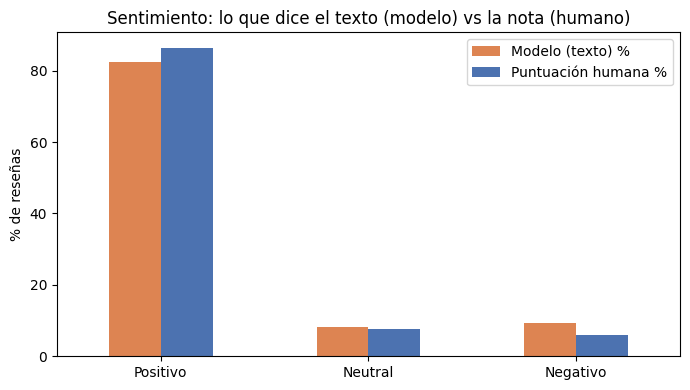

In [11]:
comparison = pd.DataFrame({
    "Modelo (texto) %": band_pct(df["sentiment_band"]),
    "Puntuación humana %": band_pct(df["human_band"]),
})
comparison["Diferencia (p.p.)"] = (comparison["Modelo (texto) %"] - comparison["Puntuación humana %"]).round(1)
display(comparison)

print(f"Promedio humano: {df['rating'].mean():.2f} estrellas")
print(f"Promedio que asigna el modelo: {df['pred_stars'].mean():.2f} estrellas")
print(f"Brecha: {df['pred_stars'].mean() - df['rating'].mean():+.2f} estrellas")

ax = comparison[["Modelo (texto) %", "Puntuación humana %"]].plot(
    kind="bar", figsize=(7, 4), color=["#DD8452", "#4C72B0"]
)
ax.set_title("Sentimiento: lo que dice el texto (modelo) vs la nota (humano)")
ax.set_ylabel("% de reseñas")
ax.set_xlabel("")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Matriz de confusión: filas = banda según la nota humana, columnas = banda según el modelo.
Las celdas fuera de la diagonal son las discrepancias.

In [12]:
confusion = pd.crosstab(
    df["human_band"], df["sentiment_band"],
    rownames=["Humano"], colnames=["Modelo"],
).reindex(index=BAND_ORDER, columns=BAND_ORDER, fill_value=0)
display(confusion)

agreement = (df["human_band"] == df["sentiment_band"]).mean() * 100
exact = (df["rating"] == df["pred_stars"]).mean() * 100
print(f"Acuerdo por banda: {agreement:.1f} %  ·  Acuerdo en estrellas exactas: {exact:.1f} %")

display(pd.crosstab(df["rating"], df["pred_stars"], rownames=["Nota humana"], colnames=["Estrellas modelo"]))

Modelo,Positivo,Neutral,Negativo
Humano,,,
Positivo,412,4,16
Neutral,0,35,3
Negativo,0,2,28


Acuerdo por banda: 95.0 %  ·  Acuerdo en estrellas exactas: 85.8 %


Estrellas modelo,1,2,3,4,5
Nota humana,,,,,
1,3,9,0,0,0
2,7,9,2,0,0
3,0,3,35,0,0
4,1,0,3,47,21
5,11,4,1,9,335


## 8. Falsos negativos

**Definición:** reseñas con nota humana de **4–5 estrellas** que el modelo clasifica con **1–2 estrellas**.

In [13]:
df["is_false_negative"] = (df["rating"] >= 4) & (df["pred_stars"] <= 2)
false_negatives = df[df["is_false_negative"]]
positives = df[df["rating"] >= 4]

print(f"Falsos negativos: {len(false_negatives)} de {len(positives)} reseñas de 4-5 ★ "
      f"({len(false_negatives) / len(positives) * 100:.1f} %)")
print(f"Otras reseñas de 4-5 ★ que el modelo deja en Neutral: "
      f"{((df['rating'] >= 4) & (df['sentiment_band'] == 'Neutral')).sum()}")

false_negatives[["review_id", "rating", "pred_stars", "pred_score", "review_text"]].head(10)

Falsos negativos: 16 de 432 reseñas de 4-5 ★ (3.7 %)
Otras reseñas de 4-5 ★ que el modelo deja en Neutral: 4


,review_id,rating,pred_stars,pred_score,review_text
13,14,4,1,0.4443,Tried Harbor House Café after seeing it recommended online. Every dish was bursting with flavor. The team clearly cares about the customers. Already planning my next visit.
14,15,5,1,0.3893,"Every dish was bursting with flavor. The place has such a cozy, welcoming vibe. Already planning my next visit."
72,73,5,1,0.2679,Stopped by Harbor House Café for the first time. Service was fast and friendly. Every dish was bursting with flavor. Worth every penny. Already planning my next visit.
86,87,5,1,0.3247,Tried Harbor House Café after seeing it recommended online. The seasonal menu never disappoints. They went out of their way to accommodate my allergy. Will definitely be back!
137,138,5,2,0.2751,"Tried Harbor House Café after seeing it recommended online. They went out of their way to accommodate my allergy. The place has such a cozy, welcoming vibe. Already planning my next visit."
199,200,5,2,0.3685,Stopped by Harbor House Café for the first time. The music and decor set the perfect mood. Every dish was bursting with flavor. Already planning my next visit.
203,204,5,1,0.3492,"Came to Harbor House Café for a birthday brunch. Every dish was bursting with flavor. The cashier was rude when i asked about the menu, but honestly the food made up for it. Already planning my ne..."
253,254,5,1,0.3641,Stopped by Harbor House Café for the first time. They went out of their way to accommodate my allergy. Great spot to work or catch up with friends. Will definitely be back!
269,270,5,1,0.4091,Stopped by Harbor House Café for the first time. Our server remembered our names by the second visit. Every dish was bursting with flavor. Great value for what you get. Will definitely be back!
321,322,5,1,0.6077,"Every dish was bursting with flavor. The staff seemed annoyed to be there, but honestly the food made up for it. Will definitely be back!"


### 8.1 ¿Qué comparten los falsos negativos?

Comparamos la tasa de error del modelo en reseñas mixtas frente a reseñas positivas "limpias".

In [14]:
error_by_mix = (
    positives.groupby("is_mixed")
    .agg(reseñas=("review_id", "count"),
         falsos_negativos=("is_false_negative", "sum"),
         estrellas_modelo_media=("pred_stars", "mean"))
    .rename(index={True: "Mixta (queja + 'but…')", False: "Solo elogios"})
)
error_by_mix["% falsos negativos"] = (error_by_mix["falsos_negativos"] / error_by_mix["reseñas"] * 100).round(1)
error_by_mix["estrellas_modelo_media"] = error_by_mix["estrellas_modelo_media"].round(2)
display(error_by_mix)

if len(false_negatives):
    print(f"De los falsos negativos, {false_negatives['is_mixed'].mean() * 100:.1f} % son reseñas mixtas.")

,reseñas,falsos_negativos,estrellas_modelo_media,% falsos negativos
is_mixed,,,,
Solo elogios,342,14,4.84,4.1
Mixta (queja + 'but…'),90,2,4.24,2.2


De los falsos negativos, 12.5 % son reseñas mixtas.


**Resultado inesperado:** la hipótesis inicial **no se cumple**. Las reseñas mixtas apenas fallan
(2 de 90, un 2,2 %): el modelo entiende bien el "pero" y les da 4,24 ★ de media.
**14 de los 16 falsos negativos son reseñas que solo contienen elogios.** Hay que buscar la causa en otro sitio.

¿Qué queja de servicio arrastra más al modelo hacia abajo? Agrupamos las reseñas mixtas según la queja concreta.

In [15]:
mixed = df[df["is_mixed"]].copy()
mixed["queja"] = mixed["review_text"].str.extract(r"([^.!?]+), but (?:honestly|overall)")[0].str.strip()
mixed["final"] = mixed["review_text"].str.extract(r", but (honestly the food made up for it|overall a solid experience)")[0]

by_complaint = (
    mixed.groupby("queja")
    .agg(reseñas=("review_id", "count"),
         estrellas_modelo_media=("pred_stars", "mean"),
         falsos_negativos=("is_false_negative", "sum"))
    .sort_values("estrellas_modelo_media")
    .round(2)
)
display(by_complaint)

display(mixed.groupby("final").agg(
    reseñas=("review_id", "count"),
    estrellas_modelo_media=("pred_stars", "mean"),
    falsos_negativos=("is_false_negative", "sum"),
).round(2))

,reseñas,estrellas_modelo_media,falsos_negativos
queja,,,
The cashier was rude when i asked about the menu,3,3.33,1
"Average service, no complaints",12,4.08,0
"Service was fine, nothing memorable",17,4.12,0
The staff were polite but a bit slow,16,4.19,0
The staff seemed annoyed to be there,17,4.24,1
We waited 25 minutes just to get water,18,4.50,0
Our server got our order wrong twice,5,4.60,0
Nobody checked on us the entire meal,2,5.00,0


,reseñas,estrellas_modelo_media,falsos_negativos
final,,,
honestly the food made up for it,21,4.29,2
overall a solid experience,69,4.23,0


### 8.2 Ejemplos documentados

In [16]:
cols = ["review_id", "rating", "pred_stars", "pred_score", "review_text"]
for _, row in false_negatives.sort_values("pred_stars").head(8)[cols].iterrows():
    print(f"#{row.review_id} · humano {row.rating}★ · modelo {row.pred_stars}★ (conf. {row.pred_score:.2f})")
    print(f"   {row.review_text}\n")

#14 · humano 4★ · modelo 1★ (conf. 0.44)
   Tried Harbor House Café after seeing it recommended online. Every dish was bursting with flavor. The team clearly cares about the customers. Already planning my next visit.

#15 · humano 5★ · modelo 1★ (conf. 0.39)
   Every dish was bursting with flavor. The place has such a cozy, welcoming vibe. Already planning my next visit.

#73 · humano 5★ · modelo 1★ (conf. 0.27)
   Stopped by Harbor House Café for the first time. Service was fast and friendly. Every dish was bursting with flavor. Worth every penny. Already planning my next visit.

#87 · humano 5★ · modelo 1★ (conf. 0.32)
   Tried Harbor House Café after seeing it recommended online. The seasonal menu never disappoints. They went out of their way to accommodate my allergy. Will definitely be back!

#254 · humano 5★ · modelo 1★ (conf. 0.36)
   Stopped by Harbor House Café for the first time. They went out of their way to accommodate my allergy. Great spot to work or catch up with friends

### 8.3 ¿Qué frases aparecen en los falsos negativos?

Como las reseñas se construyen con frases repetidas, medimos, para cada frase, en qué porcentaje de
las reseñas positivas (4–5 ★) que la contienen el modelo se equivoca.

In [17]:
positive_sentences = (
    positives.assign(sentence=positives["review_text"].str.split(r"(?<=[.!?])\s+"))
    .explode("sentence")
)
fn_by_sentence = (
    positive_sentences.groupby("sentence")
    .agg(reseñas=("review_id", "count"), falsos_negativos=("is_false_negative", "sum"))
)
fn_by_sentence["% falsos negativos"] = (fn_by_sentence["falsos_negativos"] / fn_by_sentence["reseñas"] * 100).round(1)
display(fn_by_sentence[fn_by_sentence["falsos_negativos"] > 0]
        .sort_values("% falsos negativos", ascending=False).head(8))

flavor = positives["review_text"].str.contains("bursting with flavor", regex=False)
flavor_visit = flavor & positives["review_text"].str.contains("Already planning my next visit", regex=False)
print(f"Falsos negativos con 'Every dish was bursting with flavor': {positives.loc[flavor, 'is_false_negative'].sum()} de {len(false_negatives)}")
print(f"Reseñas con 'bursting with flavor' + 'Already planning my next visit': {flavor_visit.sum()}, "
      f"de las cuales {positives.loc[flavor_visit, 'is_false_negative'].sum()} son falsos negativos")

,reseñas,falsos_negativos,% falsos negativos
sentence,,,
"The cashier was rude when i asked about the menu, but honestly the food made up for it.",3,1,33.3
Every dish was bursting with flavor.,41,12,29.3
"The staff seemed annoyed to be there, but honestly the food made up for it.",4,1,25.0
Already planning my next visit.,75,11,14.7
They went out of their way to accommodate my allergy.,38,4,10.5
Stopped by Harbor House Café for the first time.,61,6,9.8
Tried Harbor House Café after seeing it recommended online.,68,6,8.8
The team clearly cares about the customers.,49,3,6.1


Falsos negativos con 'Every dish was bursting with flavor': 12 de 16
Reseñas con 'bursting with flavor' + 'Already planning my next visit': 11, de las cuales 9 son falsos negativos


### 8.4 ¿Con cuánta seguridad se equivoca el modelo?

In [18]:
confidence = pd.DataFrame({
    "Falsos negativos": false_negatives["pred_score"].describe(),
    "Positivas acertadas": positives.loc[~positives["is_false_negative"], "pred_score"].describe(),
}).round(2)
display(confidence)

low_conf = df["pred_score"] < 0.5
disagreements = df["human_band"] != df["sentiment_band"]
print(f"Predicciones con confianza < 0,5: {low_conf.sum()} ({low_conf.mean() * 100:.1f} % del total)")
print(f"  contienen {df.loc[low_conf, 'is_false_negative'].sum()} de {df['is_false_negative'].sum()} falsos negativos")
print(f"  y {(low_conf & disagreements).sum()} de {disagreements.sum()} discrepancias totales con la nota humana")

,Falsos negativos,Positivas acertadas
count,16.00,416.00
mean,0.38,0.73
std,0.09,0.18
min,0.27,0.26
25%,0.32,0.61
50%,0.36,0.74
75%,0.42,0.89
max,0.61,0.99


Predicciones con confianza < 0,5: 73 (14.6 % del total)
  contienen 15 de 16 falsos negativos
  y 22 de 25 discrepancias totales con la nota humana


### 8.5 Hipótesis: por qué falla un modelo de productos con reseñas de servicios

**Lo que muestran los datos:**

- **12 de los 16 falsos negativos contienen la frase "Every dish was bursting with flavor"**. En las reseñas
  positivas con esa frase, el modelo falla un 29 % de las veces. Cuando además aparece
  "Already planning my next visit", falla en **9 de 11**.
- Le sigue "They went out of their way to accommodate my allergy" (4 falsos negativos).
- Las quejas de servicio con "pero…" **no** son el problema: el modelo las resuelve bien.
- El modelo duda: la confianza media de los falsos negativos es **0,38**, frente a **0,73** en los aciertos.

**Hipótesis del desajuste de dominio:** el modelo aprendió con reseñas de **productos**, donde algunas palabras
tienen otro significado:

- *"bursting"* suele aparecer en quejas de producto: bolsas o envases que revientan, costuras que se abren.
  En un restaurante, *"bursting with flavor"* es un elogio.
- *"allergy"* en reseñas de productos suele ir con reacciones alérgicas, es decir, quejas.
  Aquí es lo contrario: el local **se adaptó** a la alergia del cliente.
- Expresiones de servicio como *"planning my next visit"* o *"go out of their way"* son poco frecuentes en
  reseñas de productos, así que el modelo no tiene señal positiva que compense.

Con reseñas tan cortas, una sola palabra mal interpretada basta para hundir la predicción a 1–2 ★.

## 9. Verificación manual (19 reseñas)

Seleccionadas a mano para cubrir todas las notas (1–5 ★) y los dos tipos de reseña mixta.
La columna **lectura humana** es mi lectura del texto **antes** de mirar la predicción; después el código
compara con el modelo.

In [19]:
manual_review = {
    # review_id: (lectura humana del texto, nota)
    1:   ("Positivo", "Solo elogios: comida, ambiente y precio."),
    65:  ("Positivo", "Solo elogios: ambiente y servicio rápido."),
    14:  ("Positivo", "4★ con texto 100 % positivo."),
    273: ("Positivo", "4★ pero dice 'Five stars without hesitation'."),
    10:  ("Positivo", "Personal antipático, pero 'my go-to spot'. Mixta."),
    22:  ("Positivo", "Espera de 25 min, pero 'Will definitely be back!'. Mixta."),
    28:  ("Positivo", "Pedido equivocado dos veces, pero lo recomienda. Mixta."),
    77:  ("Positivo", "Cajero maleducado, pero ya planea volver. Mixta."),
    17:  ("Positivo", "Personal lento, 'overall a solid experience', 'Five stars'. Mixta."),
    19:  ("Positivo", "Positiva débil: termina en 'Might give it another shot'."),
    51:  ("Positivo", "Espera de 25 min, 'solid experience', 'Will be back'. Mixta."),
    21:  ("Positivo", "Café excelente, personal lento, 'go-to spot'. Mixta."),
    9:   ("Neutral",  "Sándwiches normales, personal lento. Tibia."),
    16:  ("Neutral",  "Menú repetitivo y cajero maleducado; aun así volvería. Neutral tirando a negativa."),
    25:  ("Neutral",  "'Okay', 'nothing memorable'. Neutral claro."),
    32:  ("Negativo", "Huevos fríos, cajero maleducado, no volverá."),
    115: ("Negativo", "Bollería rancia, espera larga, 'disappointing'."),
    100: ("Negativo", "Café quemado, cajero maleducado, local caótico."),
    140: ("Negativo", "Café quemado, espera, local caótico."),
}

manual = (
    pd.DataFrame.from_dict(manual_review, orient="index", columns=["lectura_humana", "nota"])
    .rename_axis("review_id").reset_index()
    .merge(df[["review_id", "rating", "is_mixed", "pred_stars", "sentiment_band", "review_text"]], on="review_id")
)
manual["¿modelo correcto?"] = manual["lectura_humana"].eq(manual["sentiment_band"]).map({True: "Sí", False: "NO"})

print(f"El modelo coincide con la lectura humana en "
      f"{(manual['¿modelo correcto?'] == 'Sí').sum()} de {len(manual)} reseñas revisadas.")
manual[["review_id", "rating", "is_mixed", "pred_stars", "sentiment_band",
        "lectura_humana", "¿modelo correcto?", "nota", "review_text"]]

El modelo coincide con la lectura humana en 18 de 19 reseñas revisadas.


,review_id,rating,is_mixed,pred_stars,sentiment_band,lectura_humana,¿modelo correcto?,nota,review_text
0,1,5,False,5,Positivo,Positivo,Sí,"Solo elogios: comida, ambiente y precio.",Visited Harbor House Café last weekend. Great spot to work or catch up with friends. Every dish was bursting with flavor. Worth every penny. Already planning my next visit.
1,65,5,False,5,Positivo,Positivo,Sí,Solo elogios: ambiente y servicio rápido.,"Tried Harbor House Café after seeing it recommended online. The place has such a cozy, welcoming vibe. Service was fast and friendly. This is now my go-to spot."
2,14,4,False,1,Negativo,Positivo,NO,4★ con texto 100 % positivo.,Tried Harbor House Café after seeing it recommended online. Every dish was bursting with flavor. The team clearly cares about the customers. Already planning my next visit.
3,273,4,False,5,Positivo,Positivo,Sí,4★ pero dice 'Five stars without hesitation'.,Best brunch i've had in months. Our server remembered our names by the second visit. Five stars without hesitation.
4,10,5,True,5,Positivo,Positivo,Sí,"Personal antipático, pero 'my go-to spot'. Mixta.","The pastries were incredible. The staff seemed annoyed to be there, but honestly the food made up for it. This is now my go-to spot."
5,22,5,True,5,Positivo,Positivo,Sí,"Espera de 25 min, pero 'Will definitely be back!'. Mixta.","Fresh ingredients you can really taste. We waited 25 minutes just to get water, but honestly the food made up for it. Will definitely be back!"
6,28,5,True,5,Positivo,Positivo,Sí,"Pedido equivocado dos veces, pero lo recomienda. Mixta.","Visited Harbor House Café last weekend. The food was absolutely delicious. Our server got our order wrong twice, but honestly the food made up for it. Highly recommend to anyone in the area."
7,77,5,True,4,Positivo,Positivo,Sí,"Cajero maleducado, pero ya planea volver. Mixta.","Visited Harbor House Café last weekend. Fresh ingredients you can really taste. The cashier was rude when i asked about the menu, but honestly the food made up for it. Already planning my next visit."
8,17,4,True,5,Positivo,Positivo,Sí,"Personal lento, 'overall a solid experience', 'Five stars'. Mixta.","Tried Harbor House Café after seeing it recommended online. The sourdough bread alone is worth the visit. The staff were polite but a bit slow, but overall a solid experience. Five stars without h..."
9,19,4,True,4,Positivo,Positivo,Sí,Positiva débil: termina en 'Might give it another shot'.,"Regular customer at Harbor House Café here. The pastries were incredible. The staff were polite but a bit slow, but overall a solid experience. Might give it another shot."


**Notas de la revisión manual:**

- **18 de 19 correctas.** Las 8 reseñas mixtas revisadas (#10, #22, #28, #77, #17, #19, #51, #21) se clasificaron
  como positivas, igual que mi lectura: el modelo entiende el "pero".
- **Único error: #14** (4 ★, modelo 1 ★, confianza 0,44). Es 100 % positiva y contiene
  "Every dish was bursting with flavor" + "Already planning my next visit", la combinación que más falla en la sección 8.3.
- **#19** (4 ★ con final tibio, "Might give it another shot"): el modelo da 4 ★, que encaja con una positiva débil.
- **#16** (3 ★, cajero maleducado): el modelo da 3 ★; el texto tiene una queja seria, pero el tono general es neutral.
- Las 4 negativas y las 3 neutrales revisadas coinciden en banda.

La revisión manual confirma el patrón: **el modelo es fiable salvo con vocabulario de servicio concreto**.

## 10. Conclusiones para la account manager

Cifras clave calculadas sobre las 500 reseñas:

In [20]:
summary = {
    "reseñas": len(df),
    "modelo_%": band_pct(df["sentiment_band"]).to_dict(),
    "humano_%": band_pct(df["human_band"]).to_dict(),
    "estrellas_modelo_media": round(float(df["pred_stars"].mean()), 2),
    "falsos_negativos": int(df["is_false_negative"].sum()),
    "fn_en_mixtas": int(df.loc[df["is_mixed"], "is_false_negative"].sum()),
    "acuerdo_bandas_%": round(float((df["human_band"] == df["sentiment_band"]).mean()) * 100, 1),
}
summary

{'reseñas': 500,
 'modelo_%': {'Positivo': 82.4, 'Neutral': 8.2, 'Negativo': 9.4},
 'humano_%': {'Positivo': 86.4, 'Neutral': 7.6, 'Negativo': 6.0},
 'estrellas_modelo_media': 4.4,
 'falsos_negativos': 16,
 'fn_en_mixtas': 2,
 'acuerdo_bandas_%': 95.0}

### En términos simples

**1. Sí, el texto de las reseñas coincide con las 4,5 estrellas.**
Según lo que escriben los clientes, el **82 % de las reseñas son positivas, el 8 % neutrales y el 9 % negativas**.
La puntuación dice 86 % / 8 % / 6 %. Traducido a estrellas, el texto equivale a **4,4** frente al **4,5** real.
El modelo y la nota coinciden en el **95 %** de las reseñas.

**2. La pequeña diferencia viene del modelo, no de los clientes.**
Hay 16 reseñas de 4–5 ★ que el modelo leyó como negativas, y al leerlas son claramente positivas.
Sin esos 16 errores, las negativas bajarían del 9,4 % al **6,2 %**, prácticamente lo mismo que dice la puntuación.
El error se debe a frases como *"Every dish was bursting with flavor"*, que un modelo entrenado con reseñas de
productos interpreta mal.

**3. Hay un mensaje útil para el negocio: el punto débil es el servicio.**
El 18 % de las reseñas (90) se quejan del servicio (esperas de 25 minutos, personal antipático,
pedidos equivocados) aunque acaben poniendo 4 o 5 estrellas porque la comida compensa.
**69 de las 72 reseñas de 4 ★ son de este tipo**: mejorar el servicio es lo que convertiría esos 4 en 5.

**4. Cómo presentar las 500 reseñas al cliente.**
- Se puede afirmar que **el sentimiento escrito respalda el 4,5**.
- Antes de entregar, conviene **revisar a mano las 73 reseñas con confianza del modelo inferior a 0,5**
  (15 % del total). Ahí están 15 de los 16 errores, así que es una revisión pequeña que elimina casi todo el ruido.

## 11. Addendum (extensión opcional): ¿hay un modelo mejor?

Probamos `tabularisai/multilingual-sentiment-analysis` (también fijado por commit) con las mismas 500 reseñas.
Devuelve 5 clases: *Very Negative, Negative, Neutral, Positive, Very Positive*.

In [21]:
ALT_MODEL_NAME = "tabularisai/multilingual-sentiment-analysis"
ALT_MODEL_REVISION = "eea032081f8d247b4303ef3565e7cec1b6f201c9"  # commit fijado

ALT_LABEL_TO_BAND = {
    "Very Negative": "Negativo", "Negative": "Negativo",
    "Neutral": "Neutral",
    "Positive": "Positivo", "Very Positive": "Positivo",
}

start = time.perf_counter()
alt_classifier = pipeline("text-classification", model=ALT_MODEL_NAME, revision=ALT_MODEL_REVISION, device=-1)
alt_outputs = alt_classifier(df["review_text"].tolist(), batch_size=32, truncation=True)
print(f"Modelo alternativo: carga + 500 reseñas en {time.perf_counter() - start:.1f} s")

df["alt_label"] = [o["label"] for o in alt_outputs]
df["alt_band"] = df["alt_label"].map(ALT_LABEL_TO_BAND)
df["alt_false_negative"] = (df["rating"] >= 4) & (df["alt_band"] == "Negativo")

models_comparison = pd.DataFrame({
    "nlptown": [
        *band_pct(df["sentiment_band"]).tolist(),
        int(df["is_false_negative"].sum()),
        int(df.loc[df["is_mixed"], "is_false_negative"].sum()),
        round((df["human_band"] == df["sentiment_band"]).mean() * 100, 1),
    ],
    "tabularisai": [
        *band_pct(df["alt_band"]).tolist(),
        int(df["alt_false_negative"].sum()),
        int(df.loc[df["is_mixed"], "alt_false_negative"].sum()),
        round((df["human_band"] == df["alt_band"]).mean() * 100, 1),
    ],
}, index=["% Positivo", "% Neutral", "% Negativo", "Falsos negativos",
          "Falsos negativos en mixtas", "Acuerdo con la nota humana %"])
models_comparison["Humano"] = [*band_pct(df["human_band"]).tolist(), 0, 0, 100.0]
display(models_comparison.astype(object))

still_failing = df[df["is_false_negative"] & df["alt_false_negative"]]
print(f"Reseñas que fallan con AMBOS modelos: {len(still_failing)}")
still_failing[["review_id", "rating", "pred_stars", "alt_label", "review_text"]].head(8)

Modelo alternativo: carga + 500 reseñas en 18.3 s


,nlptown,tabularisai,Humano
% Positivo,82.4,88.8,86.4
% Neutral,8.2,2.2,7.6
% Negativo,9.4,9.0,6.0
Falsos negativos,16.0,7.0,0.0
Falsos negativos en mixtas,2.0,0.0,0.0
Acuerdo con la nota humana %,95.0,90.6,100.0


Reseñas que fallan con AMBOS modelos: 1


,review_id,rating,pred_stars,alt_label,review_text
253,254,5,1,Negative,Stopped by Harbor House Café for the first time. They went out of their way to accommodate my allergy. Great spot to work or catch up with friends. Will definitely be back!


**Recomendación sobre el cambio de modelo:**

| | nlptown | tabularisai |
|---|---|---|
| Falsos negativos | 16 | **7** |
| Acuerdo global con la nota humana | **95,0 %** | 90,6 % |
| Neutrales detectadas | **8,2 %** (humano 7,6 %) | 2,2 % |

- `tabularisai` **reduce los falsos negativos a menos de la mitad** (16 → 7) y no falla en ninguna reseña mixta.
  Solo una reseña (#254) falla con los dos modelos.
- Pero **casi no usa la clase Neutral** (2,2 % frente al 7,6 % real): empuja las reseñas tibias a positivo o
  negativo, y por eso su acuerdo global es menor (90,6 % frente al 95 %).

**Recomendación:** no cambiar de modelo directamente para este cliente.
Para el reporte de 500 reseñas, `nlptown` da la distribución más fiel. La mejora con más impacto y menos coste
es **usar los dos a la vez**: cuando no coinciden, o cuando la confianza de `nlptown` es baja, la reseña va a
revisión humana. Si en el futuro solo importa detectar reseñas negativas (no las neutrales), `tabularisai` sería
mejor opción.